In [3]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

In [5]:
(X_train,y_train),(X_test,y_test)=keras.datasets.fashion_mnist.load_data()
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


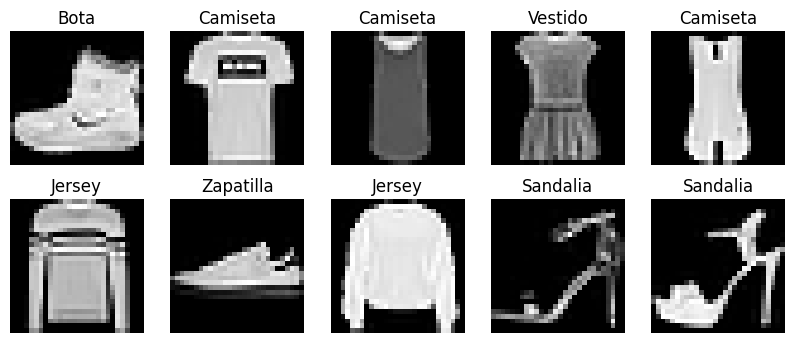

In [6]:
names = ["Camiseta","Pantalón","Jersey","Vestido","Abrigo","Sandalia","Camisa","Zapatilla","Bolso","Bota"]
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(names[y_train[i]])
    plt.axis("off")
plt.show()

train: (60000, 28, 28) uint8 | test: (10000, 28, 28)
etiquetas: (60000,) [0 1 2 3 4 5 6 7 8 9]
min/max píxel: 0 255
NaN en datos: False

Muestras por clase (train):
  0 Camiseta   6000
  1 Pantalón   6000
  2 Jersey     6000
  3 Vestido    6000
  4 Abrigo     6000
  5 Sandalia   6000
  6 Camisa     6000
  7 Zapatilla  6000
  8 Bolso      6000
  9 Bota       6000

Duplicados en las primeras 10.000: 0
Imágenes casi negras (media < 5): 1


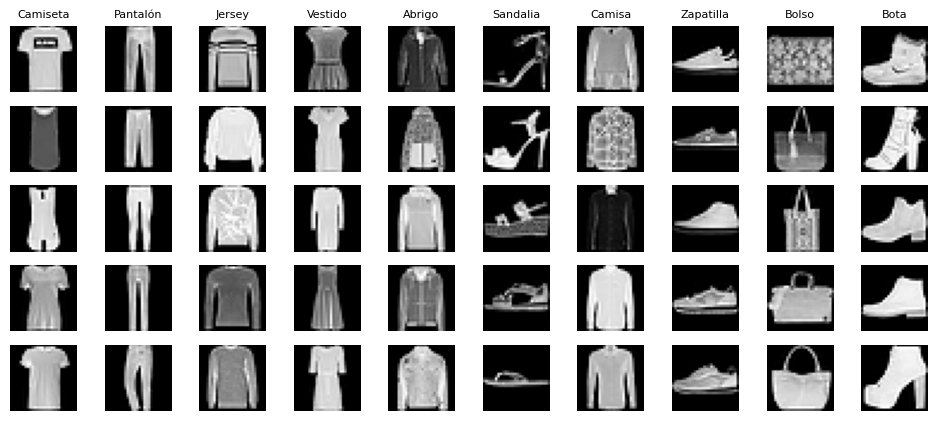

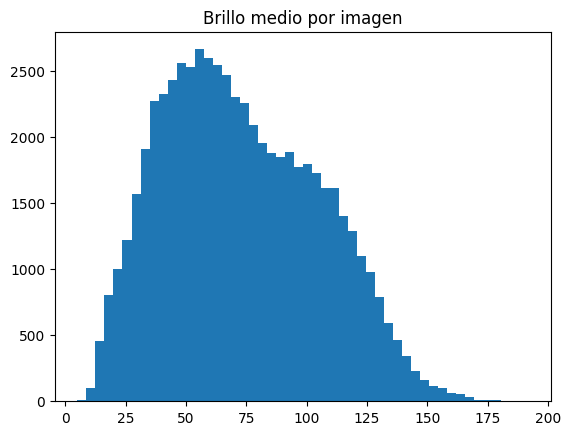

In [7]:
import numpy as np
import matplotlib.pyplot as plt

names = ["Camiseta","Pantalón","Jersey","Vestido","Abrigo","Sandalia","Camisa","Zapatilla","Bolso","Bota"]

# 1. Forma y tipo
print("train:", X_train.shape, X_train.dtype, "| test:", X_test.shape)
print("etiquetas:", y_train.shape, np.unique(y_train))

# 2. Rango de valores y valores raros (NaN)
print("min/max píxel:", X_train.min(), X_train.max())
print("NaN en datos:", np.isnan(X_train.astype(float)).any())

# 3. Balance de clases
print("\nMuestras por clase (train):")
for i, c in enumerate(np.bincount(y_train)):
    print(f"  {i} {names[i]:<10} {c}")

# 4. Duplicados exactos (ejemplo con las primeras 10.000 imágenes)
flat = X_train[:10000].reshape(10000, -1)
print("\nDuplicados en las primeras 10.000:", 10000 - len(np.unique(flat, axis=0)))

# 5. Imágenes casi vacías o saturadas
mean_px = X_train.reshape(len(X_train), -1).mean(axis=1)
print("Imágenes casi negras (media < 5):", (mean_px < 5).sum())

# 6. Mira ejemplos de cada clase
plt.figure(figsize=(12, 5))
for c in range(10):
    idx = np.where(y_train == c)[0][:5]
    for j, i in enumerate(idx):
        plt.subplot(5, 10, j * 10 + c + 1)
        plt.imshow(X_train[i], cmap="gray"); plt.axis("off")
        if j == 0: plt.title(names[c], fontsize=8)
plt.show()

# 7. Distribución de brillo
plt.hist(mean_px, bins=50); plt.title("Brillo medio por imagen"); plt.show()

PREPROCESAR


In [8]:
X_train, X_test = X_train / 255.0, X_test / 255.0   # escalar a 0-1

SEPARAR VALIDACIÓN, PORQUÉ EL TEST SE RESERVA PARA EL FINAL


In [9]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=42)

DEFINIR EL MODELO


In [11]:
from tensorflow import keras
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


ENTRENAR (INPUT: EPOCHS)

In [13]:
history = model.fit(X_train, y_train, epochs=20, batch_size=32,
                    validation_data=(X_val, y_val))

Epoch 1/20
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8165 - loss: 0.5236 - val_accuracy: 0.8451 - val_loss: 0.4236
Epoch 2/20
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8566 - loss: 0.3889 - val_accuracy: 0.8535 - val_loss: 0.4018
Epoch 3/20
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8712 - loss: 0.3486 - val_accuracy: 0.8595 - val_loss: 0.3799
Epoch 4/20
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8790 - loss: 0.3265 - val_accuracy: 0.8724 - val_loss: 0.3400
Epoch 5/20
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8863 - loss: 0.3035 - val_accuracy: 0.8744 - val_loss: 0.3427
Epoch 6/20
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8936 - loss: 0.2901 - val_accuracy: 0.8780 - val_loss: 0.3342
Epoch 7/20
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8961 - loss: 0.2769 - val_accuracy: 0.8762 - val_loss: 0.3411
Epoch 8/20
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9005 - loss: 0.2668 -

MIRAR CURVAS DE LOSS Y ACCURACY (DETECTAR OVERFITTING)


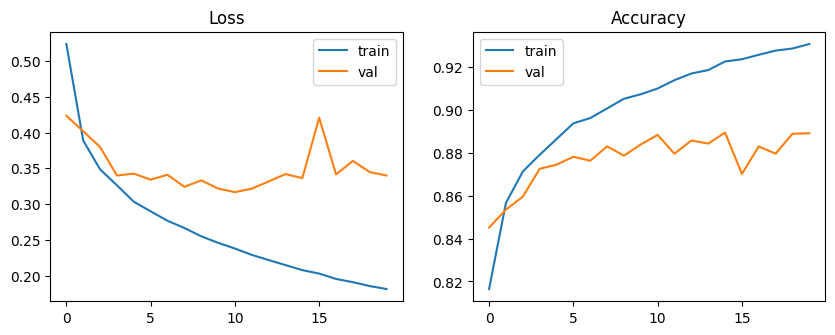

In [14]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

EVALUAR CON EL TEST


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
              precision    recall  f1-score   support

    Camiseta       0.86      0.80      0.83      1000
    Pantalón       0.99      0.97      0.98      1000
      Jersey       0.79      0.81      0.80      1000
     Vestido       0.88      0.91      0.89      1000
      Abrigo       0.82      0.79      0.81      1000
    Sandalia       0.96      0.96      0.96      1000
      Camisa       0.70      0.73      0.72      1000
   Zapatilla       0.96      0.95      0.95      1000
       Bolso       0.97      0.98      0.97      1000
        Bota       0.95      0.96      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



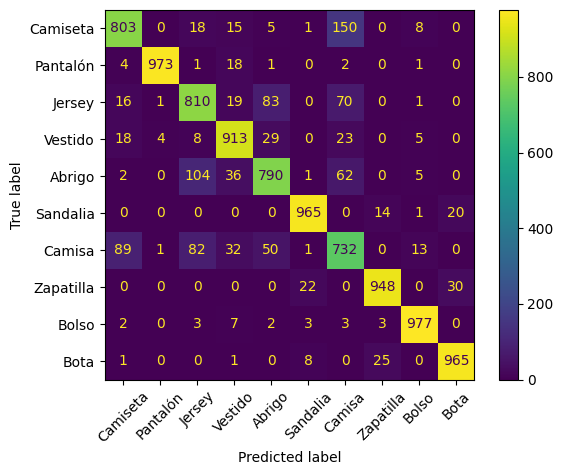

In [15]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = np.argmax(model.predict(X_test), axis=1)
print(classification_report(y_test, y_pred, target_names=names))   # accuracy, precision, recall, F1
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=names).plot(xticks_rotation=45)
plt.show()

Podemos ver que hay errores con prendas de ropa parecidas

Más adelante podemos probar con una CNN para subir el acc, o añadir un earlystopping para cuando la validación deje de mejorar

In [19]:
model.save("modelo_fashion.keras")